Wiht this notebook we want to understand the influence of the choice of the parameter k on th results of the thesis. Thereby for the different datasets we tried different k for velotest and the upper bound calculation.  

In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import yaml
import seaborn as sns
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats
import torch
from scipy import stats
from tqdm import tqdm
import velotest
from velotest.hypothesis_testing import run_hypothesis_test_on
from velotest.neighbors import find_neighbors

from matplotlib.colors import LogNorm 

In [4]:
def calculateBound(adata, k=None, neighbors=True, number_neighbors=200): 
    if neighbors is True:
        nn_indices_optimal = find_neighbors(torch.tensor(adata.layers['Ms']), k_neighbors=number_neighbors)

    mins = torch.tensor([-2.]*len(adata))
    maxs = torch.tensor([-2.]*len(adata))
    for i in tqdm(range(len(adata))):
        cos = torch.nn.CosineSimilarity(dim=1, eps=1e-6)
        if neighbors is True:
            expression_all = torch.tensor(adata.layers['Ms'][nn_indices_optimal[i]][:,adata.var.velocity_genes])
        else:
            expression_all = torch.tensor(adata.layers['Ms'][:,adata.var.velocity_genes])
        expression_cell = torch.tensor(adata.layers['Ms'][i,adata.var.velocity_genes]).unsqueeze(0)
        velocity = torch.tensor(adata.layers['velocity'][i,adata.var.velocity_genes]).unsqueeze(0)
        cosines = cos(expression_all - expression_cell, velocity)
        cosines = torch.cat([cosines[:i], cosines[i+1:]])
        if k is None:
            mins[i] = torch.min(cosines)
            maxs[i] = torch.max(cosines)
        else:
            mins[i] = torch.mean(torch.topk(cosines, largest=False, k=k).values)
            maxs[i] = torch.mean(torch.topk(cosines, largest=True, k=k).values)

    return maxs

def bestVelocityEmbedded(adata, basis, num=200):
    # Run test - tsne
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, 
                                                                           basis=basis, 
                                                                           number_neighbors_to_sample_from=num, 
                                                                           null_distribution="velocities-explicit", 
                                                                           cosine_empty_neighborhood=None, 
                                                                           correction="bonferroni", 
                                                                           restrict_to_velocity_genes=True, 
                                                                           exclusion_degree=10)
    statistics = debug_dict['statistics']

    # Calculate emmbeding test optimal statistic
    best_value = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]

    return best_value

In [5]:
datasets = {
        "Pancreas_dynamical": "../configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "../configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "../configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "../configs/gastrulation.yaml",
        "Bone_marrow": "../configs/bonemarrow.yaml",
        "PBMC": "../configs/pbmc.yaml",
        "Covid": "../configs/covid.yaml",
        "Retinal_development": "../configs/retinal_development.yaml",
        "Human_HSC": "../configs/humanHSC.yaml",
        "Intestinal_development": "../configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "../configs/noEmbedding/hindbrain.yaml",
        "Oligodendrocyte_mouse": "../configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "../configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "../configs/noEmbedding/human_cerebral.yaml",
        "Hematopoiesis_mouse": "../configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "../configs/noEmbedding/spermatogenesis.yaml",
        "Old_brain": "../configs/noEmbedding/old_brain.yaml",
        "Prefrontal_cortex": "../configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"../configs/noEmbedding/GSE128365.yaml"
    }

x = {}
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
   
    adata = sc.read(config["path"]) 
    x[name] = adata.n_obs  


Try out how the computation work before settign it in a script

In [2]:
# This whoel part was just to understand how to run everything and than this was written in a script to run in the background. 
'''
results = {}

for name, path in datasets.items():
    # Open and collect data information
    with open(path, "r") as f:
        config = yaml.safe_load(f)
    adata = sc.read(config["path"])
    
    neighbors = [2000] # Run this multiple times with different neighbors to see how it changes (merge and concatenate the files after)
    distances = {}
    # Upper bound with differnt neighbors
    for i, num in enumerate(neighbors):
        if (num+1000) >= adata.n_obs:
            print("Jump", name)
            continue
        print("noJump", name)
        upper_bound = calculateBound(adata, neighbors=True, number_neighbors=num)
    
        # Test optimal with original embedding
        bound = bestVelocityEmbedded(adata, config['basis'], num)

        distances[f"n_{num}"] = stats.wasserstein_distance(upper_bound, bound)

    results[name] = distances

df = pd.DataFrame(results)
df.to_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_2000.csv")
'''

'\nresults = {}\n\nfor name, path in datasets.items():\n    # Open and collect data information\n    with open(path, "r") as f:\n        config = yaml.safe_load(f)\n    adata = sc.read(config["path"])\n    \n    neighbors = [2000] # Run this multiple times with different neighbors to see how it changes (merge and concatenate the files after)\n    distances = {}\n    # Upper bound with differnt neighbors\n    for i, num in enumerate(neighbors):\n        if (num+1000) >= adata.n_obs:\n            print("Jump", name)\n            continue\n        print("noJump", name)\n        upper_bound = calculateBound(adata, neighbors=True, number_neighbors=num)\n    \n        # Test optimal with original embedding\n        bound = bestVelocityEmbedded(adata, config[\'basis\'], num)\n\n        distances[f"n_{num}"] = stats.wasserstein_distance(upper_bound, bound)\n\n    results[name] = distances\n\ndf = pd.DataFrame(results)\ndf.to_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_2000.csv"

In [ ]:
# Load measuremnts for all datasets
df1 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes.csv", index_col=0)
df2 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_all.csv", index_col=0)
dfo = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_oligo.csv", index_col=0)
df2o = df2.merge(dfo, left_index=True, right_index=True)
df2000_1 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_2000.csv", index_col=0)
df2000_2 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_2000_2.csv", index_col=0)
df2000 = df2000_1.merge(df2000_2, left_index=True, right_index=True)
df_complete = pd.concat([df1, df2o, df2000])
df_complete

,Pancreas_dynamical,Pancreas_stochastic,Dentate_gyrus,Gastrulation_erythroid,Bone_marrow,PBMC,Covid,Retinal_development,Human_HSC,Intestinal_development,Hindbrain_mouse,Oligodendrocyte_mouse,Bone_marrow_mouse,Cerebral_cortex_human,Hematopoiesis_mouse,Spermatogenisis,Old_brain,Prefrontal_cortex,Intestinal_organoids
n_10,0.041831,0.020482,0.019517,0.024818,0.126962,0.110775,0.042780,0.044301,0.046791,0.025152,0.055675,0.271457,0.020701,0.009829,0.010144,0.005741,0.052688,0.114195,0.019447
n_25,0.095621,0.039616,0.043918,0.065094,0.124151,0.250847,0.086137,0.105332,0.127272,0.078648,0.128281,0.193147,0.041800,0.043250,0.028473,0.021213,0.044531,0.128923,0.053941
n_50,0.148577,0.057403,0.067845,0.116808,0.184349,0.413394,0.126181,0.152687,0.229513,0.132163,0.212808,0.211932,0.100280,0.089687,0.043798,0.036109,0.093909,0.182206,0.106057
n_100,0.174910,0.065121,0.084481,0.161218,0.262546,0.569294,0.166786,0.177302,0.308744,0.192682,0.307140,0.289780,0.120787,0.126547,0.056546,0.091770,0.140575,0.206610,0.128687
n_200,0.179060,0.064260,0.092049,0.187529,0.307144,0.670491,0.195718,0.191313,0.350637,0.219767,0.365995,0.365328,0.151496,0.154265,0.069195,0.090982,0.154069,0.214268,0.165548
n_300,0.176633,0.063598,0.094787,0.198846,0.316442,0.711169,0.206046,0.193843,0.362515,0.229726,0.385195,0.402018,0.157257,0.166552,0.074252,0.082851,0.163072,NaN,0.183693
n_400,0.177339,0.063243,0.096190,0.204559,0.322152,0.733797,0.214965,0.195030,0.367269,0.234849,0.392593,0.424209,0.156585,0.175485,0.079929,0.078248,0.183972,NaN,0.194448
n_800,0.164928,0.065809,0.101574,0.215601,0.319672,0.770851,0.225391,0.161630,0.369515,0.239383,0.402475,0.467111,0.131818,0.196489,NaN,0.079867,0.245494,NaN,0.211138
n_1200,0.150711,0.067471,0.105473,0.218546,0.323341,0.782105,0.226804,0.158065,0.366704,0.238303,0.403995,0.482082,0.133913,0.206506,NaN,NaN,NaN,NaN,0.219487
n_1600,0.161580,0.067200,0.112908,0.218393,0.320709,0.786639,0.229753,0.163663,0.364361,0.238726,0.404825,0.490552,NaN,0.211337,NaN,NaN,NaN,NaN,0.224769


In [ ]:
# Save the one full table
df_complete.to_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_complete.csv")

      index               Dataset  Measurement  CellCount  Neighbors  \
0      n_10    Pancreas_dynamical     0.041831       3696         10   
1      n_25    Pancreas_dynamical     0.095621       3696         25   
2      n_50    Pancreas_dynamical     0.148577       3696         50   
3     n_100    Pancreas_dynamical     0.174910       3696        100   
4     n_200    Pancreas_dynamical     0.179060       3696        200   
..      ...                   ...          ...        ...        ...   
204   n_400  Intestinal_organoids     0.194448       3831        400   
205   n_800  Intestinal_organoids     0.211138       3831        800   
206  n_1200  Intestinal_organoids     0.219487       3831       1200   
207  n_1600  Intestinal_organoids     0.224769       3831       1600   
208  n_2000  Intestinal_organoids     0.244575       3831       2000   

     Proportion  
0      0.002706  
1      0.006764  
2      0.013528  
3      0.027056  
4      0.054113  
..          ...  
204    0.

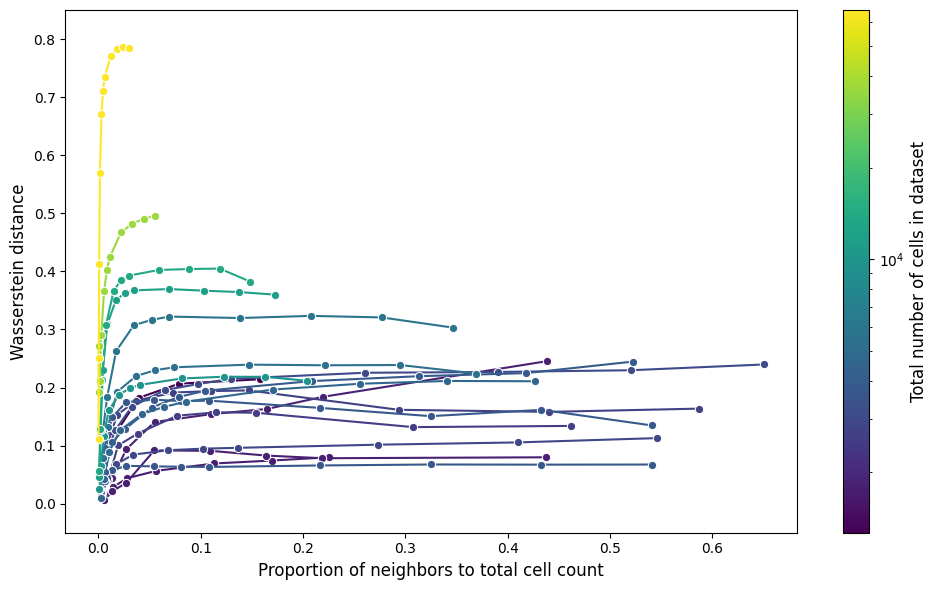

In [6]:
# Prepare dataset for plotting
df_complete = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_complete.csv", index_col=0)
count_df = pd.DataFrame(list(x.items()), columns=['Dataset', 'CellCount'])
df_long = df_complete.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')

plot_df = pd.merge(df_long, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']
print(plot_df)

# Prepare color scale 
vmin = plot_df['CellCount'].min()
vmax = plot_df['CellCount'].max()
log_norm = LogNorm(vmin=vmin, vmax=vmax)

# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_df, 
    x='Proportion', 
    y='Measurement', 
    hue='CellCount', 
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legend
if ax.get_legend() is not None:
    ax.get_legend().remove()
sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Total number of cells in dataset', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.show()

### Subsampling of datasets
To check if the trend of "less cells lower Wasserstein distance" holds true, we subsamples the datasets and recomputed the embedding and then calculated the Wasserstein distance (see script: 0519_compute_k_subsets.py)

In [5]:
subsamples = {
        '/mnt/volume/Johanna_Velotest/results/neighbors/PBMC_cluster_fractions.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Human_HSC_cluster_fractions.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Hindbrain_mouse_cluster_fractions.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Oligodendrocyte_mouse_cluster_fractions.csv'
    }

In [6]:
# Check the fractions for each cell dataset
for file in subsamples: 
    df = pd.read_csv(file, index_col=0)
    df.insert(0, 'variance', np.var(df, axis=1))
    display(df)

,variance,Hindbrain_mouse_original,Hindbrain_mouse_0.5,Hindbrain_mouse_0.25,Hindbrain_mouse_0.125
Celltype,,,,,
Neural stem cells,0.000024,0.291682,0.291556,0.295704,0.303497
Gliogenic progenitors,0.000008,0.199319,0.202667,0.206519,0.200356
GABA interneurons,0.000005,0.178802,0.176889,0.176889,0.172496
VZ progenitors,0.000005,0.145323,0.147407,0.147852,0.142264
Differentiating GABA interneurons,0.000015,0.104437,0.102963,0.096000,0.106106
Proliferating VZ progenitors,0.000004,0.080438,0.078519,0.077037,0.075282


,variance,Oligodendrocyte_mouse_original,Oligodendrocyte_mouse_0.5,Oligodendrocyte_mouse_0.25,Oligodendrocyte_mouse_0.125
Clusters,,,,,
19,2.935535e-07,0.022741,0.022464,0.023130,0.023904
21,4.364522e-06,0.043795,0.045040,0.046370,0.040726
22,2.655282e-08,0.000415,0.000332,0.000664,0.000221
26,8.300280e-06,0.173878,0.170531,0.178508,0.175520
32,1.169125e-07,0.001051,0.001328,0.001217,0.000443
34,0.000000e+00,0.000028,NaN,NaN,NaN
35,0.000000e+00,0.000055,NaN,NaN,NaN
36,8.424733e-09,0.000996,0.000996,0.001217,0.001107
37,1.424205e-05,0.242489,0.238311,0.247455,0.247233


,variance,PBMC_original,PBMC_0.5,PBMC_0.25,PBMC_0.125
celltype,,,,,
CD8+ Cytotoxic T,9.617261e-06,0.302700,0.302052,0.301293,0.309084
CD8+/CD45RA+ Naive Cytotoxic,4.106121e-06,0.243363,0.243245,0.244459,0.248239
CD56+ NK,9.075633e-07,0.128118,0.126693,0.125630,0.127641
CD4+/CD25 T Reg,4.342900e-06,0.089880,0.091019,0.091991,0.086471
CD19+ B,4.217009e-06,0.086130,0.088500,0.083187,0.084042
CD4+/CD45RO+ Memory,6.395659e-07,0.044705,0.044235,0.044933,0.042871
CD14+ Monocyte,7.705042e-07,0.041729,0.041320,0.042504,0.040078
Dendritic,1.995315e-06,0.030572,0.030330,0.033032,0.029147
CD4+/CD45RA+/CD25- Naive T,1.788504e-07,0.027354,0.026899,0.028053,0.027204


,variance,Human_HSC_original,Human_HSC_0.5,Human_HSC_0.25,Human_HSC_0.125
leiden,,,,,
LMPP,3.805343e-05,0.145541,0.148225,0.152706,0.135862
HSC,9.909724e-06,0.142352,0.142882,0.148569,0.140000
MEP,4.397057e-06,0.142094,0.140641,0.144088,0.146207
MPP,2.665327e-05,0.136579,0.130817,0.132368,0.144138
Erythrocyte,1.013216e-06,0.111159,0.108928,0.109273,0.111034
GMP,7.288217e-06,0.105730,0.106343,0.104791,0.111724
Prog MK,4.452616e-06,0.104352,0.105653,0.102723,0.100000
Granulocyte,1.787091e-05,0.063852,0.065495,0.065150,0.055172
Prog DC,2.552450e-05,0.042740,0.044640,0.036194,0.050345


      index                Dataset  Measurement  CellCount  Neighbors  \
0      n_10                   PBMC     0.110775   65877.00         10   
1      n_25                   PBMC     0.250847   65877.00         25   
2      n_50                   PBMC     0.413394   65877.00         50   
3     n_100                   PBMC     0.569294   65877.00        100   
4     n_200                   PBMC     0.670491   65877.00        200   
..      ...                    ...          ...        ...        ...   
171   n_400  Oligodendrocyte_mouse     0.456346    4518.25        400   
172   n_800  Oligodendrocyte_mouse     0.477142    4518.25        800   
173  n_1200  Oligodendrocyte_mouse     0.467113    4518.25       1200   
174  n_1600  Oligodendrocyte_mouse     0.455086    4518.25       1600   
175  n_2000  Oligodendrocyte_mouse     0.434816    4518.25       2000   

     Proportion fraction  
0      0.000152      NaN  
1      0.000379      NaN  
2      0.000759      NaN  
3      0.001518

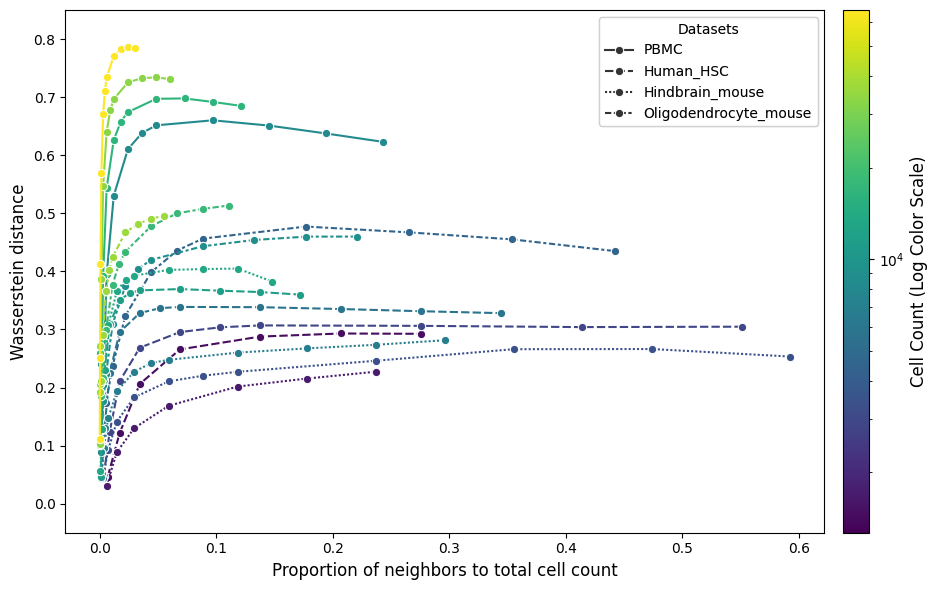

In [7]:
# Prepare dataset for plotting
df_sub = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_test.csv", index_col=0)
df_complete = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_complete.csv", index_col=0)
df_complete = df_complete[['PBMC', 'Human_HSC', 'Hindbrain_mouse', 'Oligodendrocyte_mouse']]
count_df = pd.DataFrame(list(x.items()), columns=['Dataset', 'CellCount'])

df_l_s = df_sub.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')
df_l_s['fraction'] = df_l_s['Dataset'].str.split('_').str[-1]
df_l_s['Dataset'] = df_l_s['Dataset'].str.rsplit('_', n=1).str[0]

plot_s = pd.merge(df_l_s, count_df, on='Dataset')
plot_s['Neighbors'] = plot_s['index'].str.replace('n_', '').astype(int)
plot_s['CellCount'] = plot_s['CellCount']*plot_s['fraction'].astype(float)
plot_s['Proportion'] = plot_s['Neighbors'] / plot_s['CellCount']

df_long = df_complete.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')

plot_df = pd.merge(df_long, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']

plot_complete = pd.concat([plot_df, plot_s], ignore_index=True)
print(plot_complete)


# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_complete, 
    x='Proportion', 
    y='Measurement', 
    hue='CellCount', 
    style='Dataset',    
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legends
handles, labels = ax.get_legend_handles_labels()
unique_datasets = plot_s['Dataset'].unique()
style_handles = []
style_labels = []

for h, l in zip(handles, labels):
    if l in unique_datasets:
        style_handles.append(h)
        style_labels.append(l)

if ax.get_legend() is not None:
    ax.get_legend().remove()
dataset_legend = ax.legend(
    style_handles, 
    style_labels, 
    title="Datasets", 
    loc='upper right',
    frameon=True
)
ax.add_artist(dataset_legend) # Prevents the colorbar from overwriting this legend

sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02) # Subtle pad to space it from the plot
cbar.set_label('Cell Count (Log Color Scale)', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.show()

      index                Dataset  Measurement  CellCount  Neighbors  \
0      n_10                   PBMC     0.110775   65877.00         10   
1      n_25                   PBMC     0.250847   65877.00         25   
2      n_50                   PBMC     0.413394   65877.00         50   
3     n_100                   PBMC     0.569294   65877.00        100   
4     n_200                   PBMC     0.670491   65877.00        200   
..      ...                    ...          ...        ...        ...   
171   n_400  Oligodendrocyte_mouse     0.472815    4518.25        400   
172   n_800  Oligodendrocyte_mouse     0.503308    4518.25        800   
173  n_1200  Oligodendrocyte_mouse     0.508357    4518.25       1200   
174  n_1600  Oligodendrocyte_mouse     0.501615    4518.25       1600   
175  n_2000  Oligodendrocyte_mouse     0.493128    4518.25       2000   

     Proportion fraction  
0      0.000152      NaN  
1      0.000379      NaN  
2      0.000759      NaN  
3      0.001518

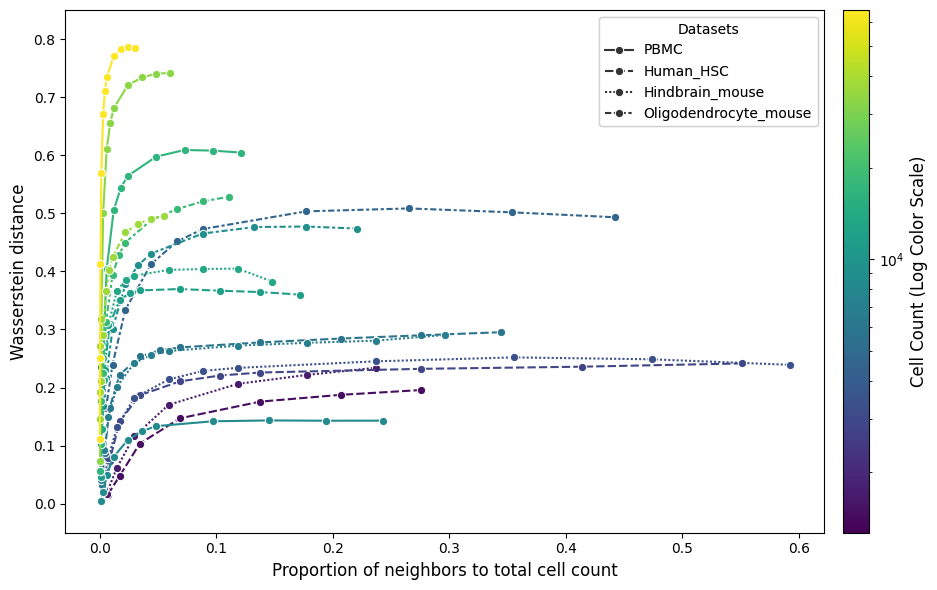

In [8]:
# Prepare dataset for plotting
df_sub = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_subsample_recomputed.csv", index_col=0)
df_complete = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_complete.csv", index_col=0)
df_complete = df_complete[['PBMC', 'Human_HSC', 'Hindbrain_mouse', 'Oligodendrocyte_mouse']]
count_df = pd.DataFrame(list(x.items()), columns=['Dataset', 'CellCount'])

df_l_s = df_sub.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')
df_l_s['fraction'] = df_l_s['Dataset'].str.split('_').str[-1]
df_l_s['Dataset'] = df_l_s['Dataset'].str.rsplit('_', n=1).str[0]

plot_s = pd.merge(df_l_s, count_df, on='Dataset')
plot_s['Neighbors'] = plot_s['index'].str.replace('n_', '').astype(int)
plot_s['CellCount'] = plot_s['CellCount']*plot_s['fraction'].astype(float)
plot_s['Proportion'] = plot_s['Neighbors'] / plot_s['CellCount']

df_long = df_complete.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')

plot_df = pd.merge(df_long, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']

plot_complete = pd.concat([plot_df, plot_s], ignore_index=True)
print(plot_complete)

# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_complete, 
    x='Proportion', 
    y='Measurement', 
    hue='CellCount', 
    style='Dataset',    
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legends
handles, labels = ax.get_legend_handles_labels()
unique_datasets = plot_s['Dataset'].unique()
style_handles = []
style_labels = []

for h, l in zip(handles, labels):
    if l in unique_datasets:
        style_handles.append(h)
        style_labels.append(l)

if ax.get_legend() is not None:
    ax.get_legend().remove()
dataset_legend = ax.legend(
    style_handles, 
    style_labels, 
    title="Datasets", 
    loc='upper right',
    frameon=True
)
ax.add_artist(dataset_legend) # Prevents the colorbar from overwriting this legend

sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02) # Subtle pad to space it from the plot
cbar.set_label('Cell Count (Log Color Scale)', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.show()

### Subsampling of datasets to a certain cell number
To check if the trend of "less cells lower Wasserstein distance" holds true, we subsamples the datasets and recomputed the embedding and then calculated the Wasserstein distance (see script: 0519_compute_k_subsets.py) --> adapted this script to subsmaple exactly 5000 cells


In [9]:
subsamples = {
        '/mnt/volume/Johanna_Velotest/results/neighbors/PBMC_cluster_cells_recomputed.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Human_HSC_cluster_cells_recomputed.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Hindbrain_mouse_cluster_cells_recomputed.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Oligodendrocyte_mouse_cluster_cells_recomputed.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Gastrulation_erythroid_cluster_cells_recomputed.csv'
    }

# Check the fractions for each cell dataset
for file in subsamples: 
    df = pd.read_csv(file, index_col=0)
    df.insert(0, 'variance', np.var(df, axis=1))
    display(df)

,variance,Hindbrain_mouse_original,Hindbrain_mouse_[5000]
Celltype,,,
Neural stem cells,1.163143e-07,0.291682,0.2910
Gliogenic progenitors,9.981079e-06,0.199319,0.1930
GABA interneurons,2.887331e-06,0.178802,0.1822
VZ progenitors,3.758618e-06,0.145323,0.1492
Differentiating GABA interneurons,6.666037e-09,0.104437,0.1046
Proliferating VZ progenitors,4.806750e-08,0.080438,0.0800


,variance,Gastrulation_erythroid_original,Gastrulation_erythroid_[5000]
celltype,,,
Erythroid1,8.470383e-06,0.298421,0.2926
Erythroid3,6.532724e-07,0.274783,0.2764
Blood progenitors 2,6.158387e-06,0.250637,0.2556
Erythroid2,5.097060e-06,0.112685,0.1172
Blood progenitors 1,6.954492e-06,0.063474,0.0582


,variance,Oligodendrocyte_mouse_original,Oligodendrocyte_mouse_[5000]
Clusters,,,
19,2.339209e-06,0.022741,0.0258
21,3.567737e-07,0.043795,0.0426
22,3.705939e-08,0.000415,0.0008
26,1.197796e-05,0.173878,0.1808
32,3.039932e-08,0.001051,0.0014
34,0.000000e+00,0.000028,NaN
35,0.000000e+00,0.000055,NaN
36,4.081191e-08,0.000996,0.0014
37,6.531103e-06,0.242489,0.2476


,variance,PBMC_original,PBMC_[5000]
celltype,,,
CD4+ T Helper2,3.931140e-08,0.001397,0.0010
CD4+/CD25 T Reg,2.073059e-06,0.089880,0.0870
CD4+/CD45RA+/CD25- Naive T,7.673128e-08,0.027354,0.0268
CD4+/CD45RO+ Memory,1.568161e-06,0.044705,0.0422
CD8+ Cytotoxic T,4.228168e-07,0.302700,0.3014
CD8+/CD45RA+ Naive Cytotoxic,6.612158e-09,0.243363,0.2432
CD14+ Monocyte,2.158919e-07,0.041729,0.0408
CD19+ B,9.210580e-06,0.086130,0.0922
CD34+,7.024588e-10,0.004053,0.0040


,variance,Human_HSC_original,Human_HSC_[5000]
leiden,,,
LMPP,1.680715e-08,0.145541,0.1458
HSC,1.628730e-06,0.142352,0.1398
MEP,6.487018e-06,0.142094,0.1370
MPP,4.041988e-06,0.136579,0.1406
Erythrocyte,8.529369e-06,0.111159,0.1170
GMP,3.478763e-06,0.105730,0.1020
Prog MK,1.753542e-06,0.104352,0.1070
Granulocyte,3.031290e-08,0.063852,0.0642
Prog DC,3.250130e-07,0.042740,0.0416


      index                 Dataset  Measurement  CellCount  Neighbors  \
0      n_10                    PBMC     0.110775    65877.0         10   
1      n_25                    PBMC     0.250847    65877.0         25   
2      n_50                    PBMC     0.413394    65877.0         50   
3     n_100                    PBMC     0.569294    65877.0        100   
4     n_200                    PBMC     0.670491    65877.0        200   
..      ...                     ...          ...        ...        ...   
105   n_400  Gastrulation_erythroid     0.185530     5000.0        400   
106   n_800  Gastrulation_erythroid     0.192448     5000.0        800   
107  n_1200  Gastrulation_erythroid     0.194815     5000.0       1200   
108  n_1600  Gastrulation_erythroid     0.197553     5000.0       1600   
109  n_2000  Gastrulation_erythroid     0.200062     5000.0       2000   

     Proportion fraction  
0      0.000152      NaN  
1      0.000379      NaN  
2      0.000759      NaN  
3  

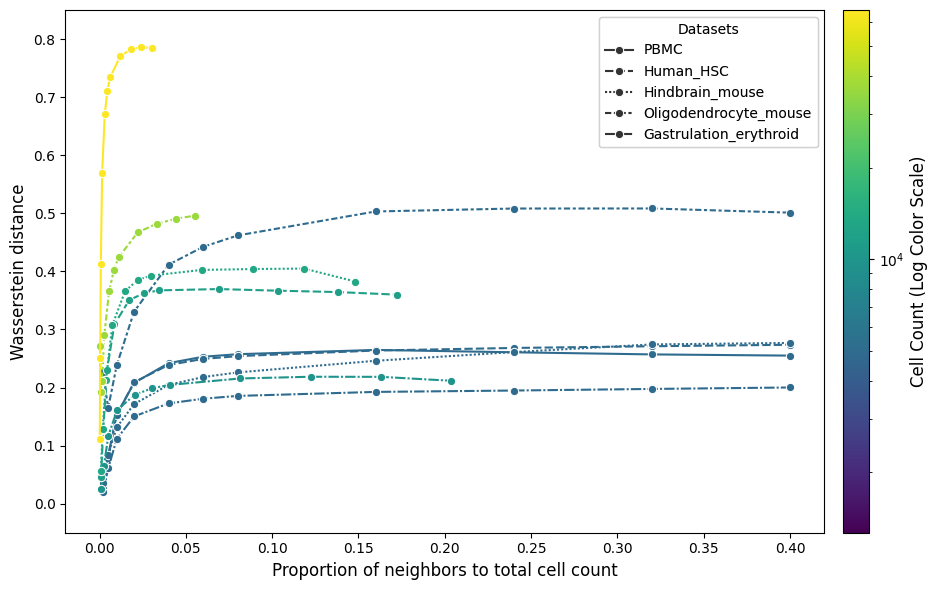

In [10]:
# Prepare dataset for plotting
df_sub = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_subsample_recomputed_cells.csv", index_col=0)
df_complete = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_complete.csv", index_col=0)
df_complete = df_complete[['PBMC', 'Human_HSC', 'Hindbrain_mouse', 'Oligodendrocyte_mouse', 'Gastrulation_erythroid']]
count_df = pd.DataFrame(list(x.items()), columns=['Dataset', 'CellCount'])

df_l_s = df_sub.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')
df_l_s['fraction'] = "5000"
df_l_s['Dataset'] = df_l_s['Dataset'].str.rsplit('_', n=1).str[0]

plot_s = pd.merge(df_l_s, count_df, on='Dataset')
plot_s['Neighbors'] = plot_s['index'].str.replace('n_', '').astype(int)
plot_s['CellCount'] = plot_s['fraction'].astype(float)
plot_s['Proportion'] = plot_s['Neighbors'] / plot_s['CellCount']

df_long = df_complete.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')

plot_df = pd.merge(df_long, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']

plot_complete = pd.concat([plot_df, plot_s], ignore_index=True)
print(plot_complete)

# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_complete, 
    x='Proportion', 
    y='Measurement', 
    hue='CellCount', 
    style='Dataset',    
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legends
handles, labels = ax.get_legend_handles_labels()
unique_datasets = plot_s['Dataset'].unique()
style_handles = []
style_labels = []

for h, l in zip(handles, labels):
    if l in unique_datasets:
        style_handles.append(h)
        style_labels.append(l)

if ax.get_legend() is not None:
    ax.get_legend().remove()
dataset_legend = ax.legend(
    style_handles, 
    style_labels, 
    title="Datasets", 
    loc='upper right',
    frameon=True
)
ax.add_artist(dataset_legend) # Prevents the colorbar from overwriting this legend

sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02) # Subtle pad to space it from the plot
cbar.set_label('Cell Count (Log Color Scale)', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.show()

     index               Dataset  Measurement fraction  CellCount  Neighbors  \
0     n_10    Pancreas_dynamical     0.032677     5000       3696         10   
1     n_25    Pancreas_dynamical     0.074961     5000       3696         25   
2     n_50    Pancreas_dynamical     0.108980     5000       3696         50   
3    n_100    Pancreas_dynamical     0.130683     5000       3696        100   
4    n_200    Pancreas_dynamical     0.137695     5000       3696        200   
..     ...                   ...          ...      ...        ...        ...   
115  n_100  Intestinal_organoids     0.152181     5000       3831        100   
116  n_200  Intestinal_organoids     0.185677     5000       3831        200   
117  n_300  Intestinal_organoids     0.202526     5000       3831        300   
118  n_400  Intestinal_organoids     0.211318     5000       3831        400   
119  n_800  Intestinal_organoids     0.237605     5000       3831        800   

     Proportion  
0        0.0050  
1  

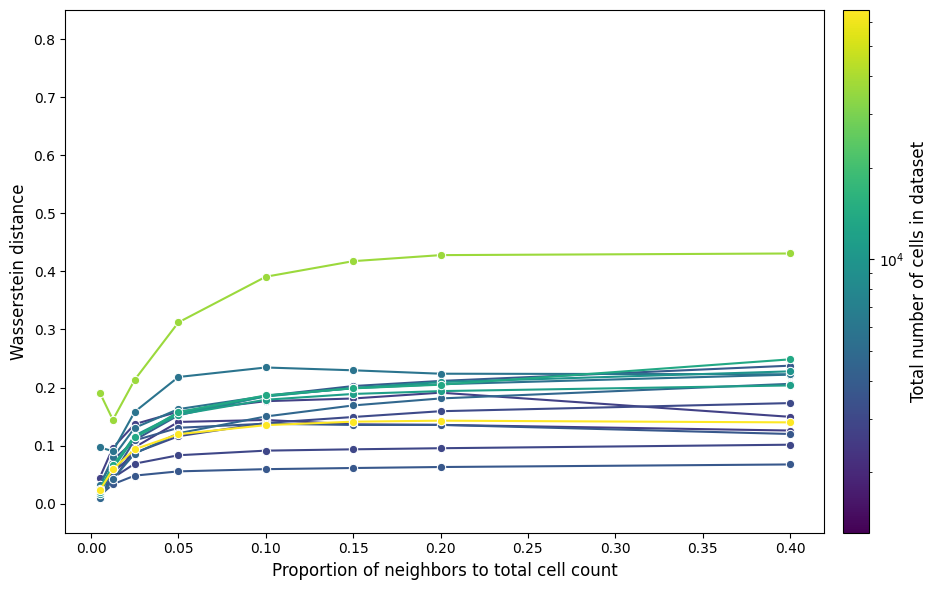

In [7]:
# Prepare dataset for plotting
df_sub = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_subsample_recomputed_2000cells.csv", index_col=0)
df_complete = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_complete.csv", index_col=0)
count_df = pd.DataFrame(list(x.items()), columns=['Dataset', 'CellCount'])

df_l_s = df_sub.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')
df_l_s['fraction'] = "5000"
df_l_s['Dataset'] = df_l_s['Dataset'].str.rsplit('_', n=1).str[0]

plot_s = pd.merge(df_l_s, count_df, on='Dataset')
plot_s['Neighbors'] = plot_s['index'].str.replace('n_', '').astype(int)
#plot_s['CellCount'] = plot_s['fraction'].astype(float)
plot_s['Proportion'] = plot_s['Neighbors'] / 2000

plot_complete = plot_s.copy()
print(plot_complete)

# Plot graph
plt.figure(figsize=(10, 6))


ax = sns.lineplot(
    data=plot_complete, 
    x='Proportion', 
    y='Measurement', 
    hue='CellCount',    
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)
ax.legend_.remove() # Remove legend to only have the colorbar
sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02) # Subtle pad to space it from the plot
cbar.set_label('Total number of cells in dataset', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.show()

After we considered, that the dimesnio of velocity genes might have a higher influence than cell number I plottd the two main graphs again, building the color scale based on the velocity gene (dimensions) 

In [10]:
datasets = {
        "Pancreas_dynamical": "../configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "../configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "../configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "../configs/gastrulation.yaml",
        "Bone_marrow": "../configs/bonemarrow.yaml",
        "PBMC": "../configs/pbmc.yaml",
        "Covid": "../configs/covid.yaml",
        "Retinal_development": "../configs/retinal_development.yaml",
        "Human_HSC": "../configs/humanHSC.yaml",
        "Intestinal_development": "../configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "../configs/noEmbedding/hindbrain.yaml",
        "Oligodendrocyte_mouse": "../configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "../configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "../configs/noEmbedding/human_cerebral.yaml",
        "Hematopoiesis_mouse": "../configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "../configs/noEmbedding/spermatogenesis.yaml",
        "Old_brain": "../configs/noEmbedding/old_brain.yaml",
        "Prefrontal_cortex": "../configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"../configs/noEmbedding/GSE128365.yaml"
    }

v = {}
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
   
    adata = sc.read(config["path"]) 
    v[name] = np.sum(adata.var.velocity_genes)


      index               Dataset  Measurement  Genes  CellCount  Neighbors  \
0      n_10    Pancreas_dynamical     0.041831   1027       3696         10   
1      n_25    Pancreas_dynamical     0.095621   1027       3696         25   
2      n_50    Pancreas_dynamical     0.148577   1027       3696         50   
3     n_100    Pancreas_dynamical     0.174910   1027       3696        100   
4     n_200    Pancreas_dynamical     0.179060   1027       3696        200   
..      ...                   ...          ...    ...        ...        ...   
204   n_400  Intestinal_organoids     0.194448    157       3831        400   
205   n_800  Intestinal_organoids     0.211138    157       3831        800   
206  n_1200  Intestinal_organoids     0.219487    157       3831       1200   
207  n_1600  Intestinal_organoids     0.224769    157       3831       1600   
208  n_2000  Intestinal_organoids     0.244575    157       3831       2000   

     Proportion  
0      0.002706  
1      0.006764

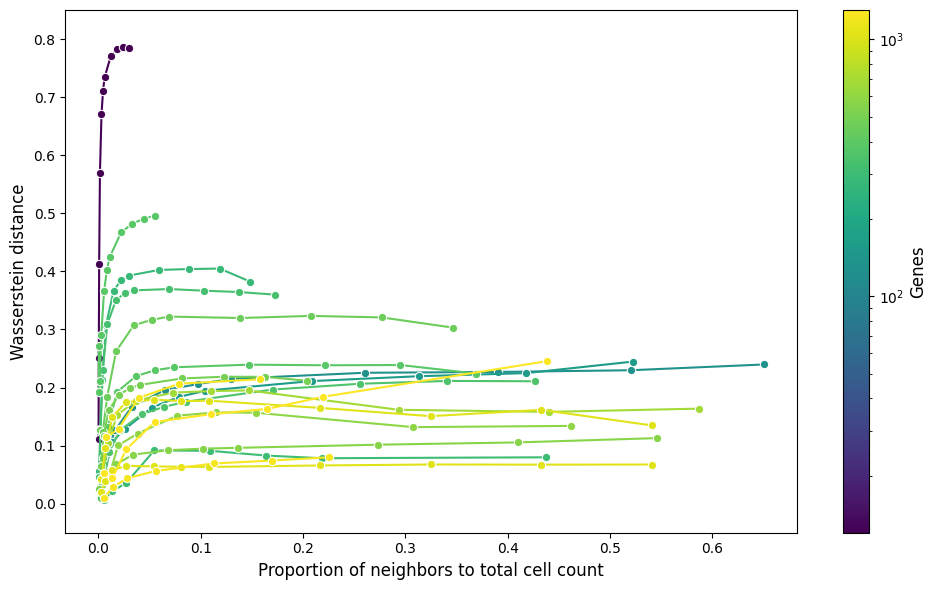

In [14]:
# Prepare dataset for plotting
df_complete = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_complete.csv", index_col=0)
count_df = pd.DataFrame(list(x.items()), columns=['Dataset', 'CellCount'])
gene_df = pd.DataFrame(list(v.items()), columns=['Dataset', 'Genes'])
df_long = df_complete.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')
plot_s = pd.merge(df_long, gene_df, on='Dataset')

plot_df = pd.merge(plot_s, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']
print(plot_df)

# Prepare color scale 
vmin = plot_df['Genes'].min()
vmax = plot_df['Genes'].max()
log_norm = LogNorm(vmin=vmin, vmax=vmax)

# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_df, 
    x='Proportion', 
    y='Measurement', 
    hue='Genes', 
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legend
if ax.get_legend() is not None:
    ax.get_legend().remove()
sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Genes', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.show()

     index               Dataset  Measurement  Genes  Neighbors  Proportion
0     n_10    Pancreas_dynamical     0.032677   1027         10      0.0050
1     n_25    Pancreas_dynamical     0.074961   1027         25      0.0125
2     n_50    Pancreas_dynamical     0.108980   1027         50      0.0250
3    n_100    Pancreas_dynamical     0.130683   1027        100      0.0500
4    n_200    Pancreas_dynamical     0.137695   1027        200      0.1000
..     ...                   ...          ...    ...        ...         ...
115  n_100  Intestinal_organoids     0.152181    157        100      0.0500
116  n_200  Intestinal_organoids     0.185677    157        200      0.1000
117  n_300  Intestinal_organoids     0.202526    157        300      0.1500
118  n_400  Intestinal_organoids     0.211318    157        400      0.2000
119  n_800  Intestinal_organoids     0.237605    157        800      0.4000

[120 rows x 6 columns]


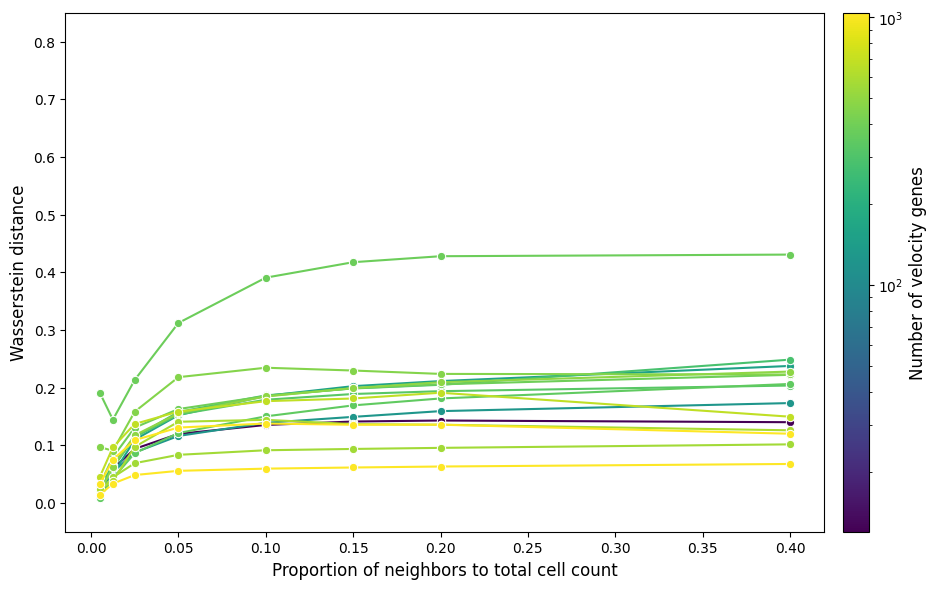

In [11]:
# Prepare dataset for plotting
df_sub = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_subsample_recomputed_2000cells.csv", index_col=0)
df_complete = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_complete.csv", index_col=0)
gene_df = pd.DataFrame(list(v.items()), columns=['Dataset', 'Genes'])

df_l_s = df_sub.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')
df_l_s['Dataset'] = df_l_s['Dataset'].str.rsplit('_', n=1).str[0]

plot_s = pd.merge(df_l_s, gene_df, on='Dataset')
plot_s['Neighbors'] = plot_s['index'].str.replace('n_', '').astype(int)
plot_s['Proportion'] = plot_s['Neighbors'] / 2000

plot_complete = plot_s.copy()
print(plot_complete)

# Plot graph
plt.figure(figsize=(10, 6))
# Prepare color scale 
vmin = plot_s['Genes'].min()
vmax = plot_s['Genes'].max()
log_norm = LogNorm(vmin=vmin, vmax=vmax)

ax = sns.lineplot(
    data=plot_complete, 
    x='Proportion', 
    y='Measurement', 
    hue='Genes',    
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)
ax.legend_.remove() # Remove legend to only have the colorbar
sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02) # Subtle pad to space it from the plot
cbar.set_label('Number of velocity genes', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.show()